In [9]:
from pathlib import Path
import pandas as pd

# Define path to local dataset folder using pathlib
DATASET_DIR = Path("dataset")


def load_titanic_data(filename: str = "train.csv", path: Path = DATASET_DIR) -> pd.DataFrame:
    """Loads a Titanic CSV file from the local dataset directory into a Pandas DataFrame."""
    csv_path = path / filename

    if not csv_path.exists():
        raise FileNotFoundError(
            f"Could not find '{filename}' in '{path.resolve()}'. "
            "Please verify the file exists inside your 'dataset/' folder."
        )

    return pd.read_csv(csv_path)


# Load both datasets into separate DataFrames
train_df = load_titanic_data("train.csv")
test_df = load_titanic_data("test.csv")

# Display the first 50 rows of train_df
train_df.head(50)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [3]:
titanic.info


<bound method DataFrame.info of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                   

In [4]:
titanic.shape


(891, 12)

In [5]:
titanic.columns


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [6]:
titanic.describe


<bound method DataFrame.describe of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                               

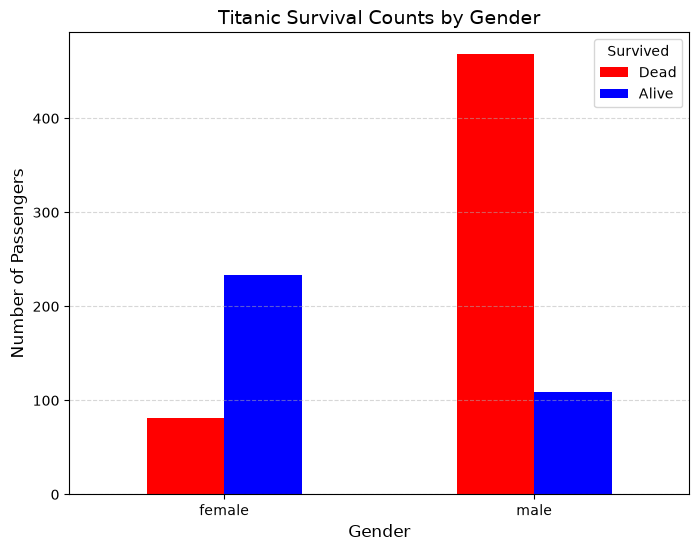

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Create a cross-tabulation table mapping 0 -> Dead and 1 -> Alive
survival_by_sex = pd.crosstab(
    titanic["Sex"], titanic["Survived"].map({0: "Dead", 1: "Alive"})
)

# 2. Ensure 'Dead' comes first so the colors match correctly
survival_by_sex = survival_by_sex[["Dead", "Alive"]]

# 3. Plot grouped bar chart using Matplotlib backend
ax = survival_by_sex.plot(
    kind="bar",
    color=["red", "blue"],  # Dead = Red, Alive = Blue
    figsize=(8, 6),
    rot=0,  # Keeps 'female' and 'male' x-axis labels horizontal
)

# 4. Add titles and labels
plt.title("Titanic Survival Counts by Gender", fontsize=14)
plt.xlabel("Gender", fontsize=12)
plt.ylabel("Number of Passengers", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [10]:
# 1. Display data types and memory usage
print("=== Dataset Info ===")
train_df.info()

# 2. Count missing values per column sorted descending
print("\n=== Missing Values in Train ===")
missing_train = train_df.isnull().sum()
print(missing_train[missing_train > 0].sort_values(ascending=False))

# 3. Summary statistics for numerical features
print("\n=== Statistical Summary ===")
train_df.describe()

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

=== Missing Values in Train ===
Cabin       687
Age         177
Embarked      2
dtype: int64

=== Statistical Summary ===


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [14]:
# 1. Safely drop 'Cabin' (errors="ignore" prevents KeyError if re-run)
train_df.drop(columns=["Cabin"], inplace=True, errors="ignore")
test_df.drop(columns=["Cabin"], inplace=True, errors="ignore")

# 2. Calculate statistics strictly from train_df to prevent data leakage
age_median = train_df["Age"].median()
embarked_mode = train_df["Embarked"].mode()[0]
fare_median = test_df[
    "Fare"
].median()  # Fallback for missing fare in test_df

# 3. Impute missing values in train_df
train_df["Age"] = train_df["Age"].fillna(age_median)
train_df["Embarked"] = train_df["Embarked"].fillna(embarked_mode)

# 4. Apply the SAME training statistics to test_df
test_df["Age"] = test_df["Age"].fillna(age_median)
test_df["Embarked"] = test_df["Embarked"].fillna(embarked_mode)
test_df["Fare"] = test_df["Fare"].fillna(fare_median)

# 5. Verify no null values remain in key columns
print("Missing values in train_df:")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])

print("\nMissing values in test_df:")
print(test_df.isnull().sum()[test_df.isnull().sum() > 0])

Missing values in train_df:
Series([], dtype: int64)

Missing values in test_df:
Series([], dtype: int64)


/tmp/ipykernel_42807/2407843816.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train_df.drop(columns=["Cabin"], inplace=True, errors="ignore")
/tmp/ipykernel_42807/2407843816.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test_df.drop(columns=["Cabin"], inplace=True, errors="ignore")


In [15]:
for df in [train_df, test_df]:
    # Total family size including the passenger themselves
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    # Binary flag: 1 if traveling alone, 0 otherwise
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Inspect the survival rate by family size in training data
train_df[["FamilySize", "Survived"]].groupby("FamilySize").mean()

,Survived
FamilySize,
1,0.303538
2,0.552795
3,0.578431
4,0.724138
5,0.200000
6,0.136364
7,0.333333
8,0.000000
11,0.000000


In [16]:
# 1. Extract titles using regex (captures words ending with a dot)
for df in [train_df, test_df]:
    df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)

# 2. Group rare/noble titles into standard categories
rare_titles = [
    "Lady",
    "Countess",
    "Capt",
    "Col",
    "Don",
    "Dr",
    "Major",
    "Rev",
    "Sir",
    "Jonkheer",
    "Dona",
]

for df in [train_df, test_df]:
    df["Title"] = df["Title"].replace(rare_titles, "Rare")
    df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

# Check title distribution and survival rates
train_df[["Title", "Survived"]].groupby("Title").agg(["count", "mean"])

Survived          
          count      mean
Title                    
Master       40  0.575000
Miss        185  0.702703
Mr          517  0.156673
Mrs         126  0.793651
Rare         23  0.347826

In [17]:
# 1. Define categorical columns to one-hot encode
cat_cols = ["Sex", "Embarked", "Title"]

# 2. Apply One-Hot Encoding across both train and test DataFrames
train_encoded = pd.get_dummies(train_df, columns=cat_cols, drop_first=True)
test_encoded = pd.get_dummies(test_df, columns=cat_cols, drop_first=True)

# 3. Ensure both DataFrames have matching encoded columns
train_encoded, test_encoded = train_encoded.align(
    test_encoded, join="left", axis=1, fill_value=0
)

# 4. Separate features (X) and target variable (y)
X_train = train_encoded.drop(
    columns=["Survived", "PassengerId", "Name", "Ticket"]
)
y_train = train_encoded["Survived"].astype(int)

# Prepare test set features (drop Survived column which was added during alignment)
X_test = test_encoded.drop(
    columns=["Survived", "PassengerId", "Name", "Ticket"]
)

# Verify dataset shapes
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")


X_train shape: (891, 14)
y_train shape: (891,)
X_test shape: (418, 14)


In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Define Stratified 5-Fold Cross-Validation strategy
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Model 1: Logistic Regression Pipeline (scaling is essential for linear models)
log_reg_pipe = make_pipeline(
    StandardScaler(), LogisticRegression(random_state=42, max_iter=1000)
)
log_reg_scores = cross_val_score(
    log_reg_pipe, X_train, y_train, cv=skf, scoring="accuracy"
)

# 3. Model 2: Random Forest Classifier (tree models don't require feature scaling)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_scores = cross_val_score(rf_clf, X_train, y_train, cv=skf, scoring="accuracy")

# 4. Display comparative baseline results
print("=== Baseline Cross-Validation Accuracy ===")
print(
    f"Logistic Regression: {log_reg_scores.mean():.4f} (+/- {log_reg_scores.std():.4f})"
)
print(f"Random Forest:       {rf_scores.mean():.4f} (+/- {rf_scores.std():.4f})")

=== Baseline Cross-Validation Accuracy ===
Logistic Regression: 0.8294 (+/- 0.0112)
Random Forest:       0.8159 (+/- 0.0108)


In [19]:
from sklearn.model_selection import GridSearchCV

# 1. Feature Importance Analysis (Random Forest)
rf_clf.fit(X_train, y_train)
importances = pd.Series(
    rf_clf.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

print("=== Top 8 Most Important Features ===")
print(importances.head(8))
print("-" * 40)

# 2. Hyperparameter Tuning for Random Forest using GridSearchCV
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1,  # Uses all CPU cores
)

grid_search.fit(X_train, y_train)

print(f"Tuned Random Forest Best CV Score: {grid_search.best_score_:.4f}")
print("Best Hyperparameters:", grid_search.best_params_)

=== Top 8 Most Important Features ===
Fare          0.233857
Age           0.220747
Title_Mr      0.140782
Sex_male      0.111153
Pclass        0.081126
FamilySize    0.048277
Title_Miss    0.037679
SibSp         0.029501
dtype: float64
----------------------------------------
Tuned Random Forest Best CV Score: 0.8451
Best Hyperparameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}


In [20]:
# 1. Extract the best model selected by GridSearchCV
best_rf = grid_search.best_estimator_

# 2. Generate predictions on the test dataset
test_predictions = best_rf.predict(X_test)

# 3. Construct the submission DataFrame matching Kaggle's required format
submission = pd.DataFrame(
    {"PassengerId": test_df["PassengerId"], "Survived": test_predictions}
)

# 4. Export to CSV without the Pandas index column
submission.to_csv("submission.csv", index=False)
print("Submission file successfully created: 'submission.csv'")

# 5. Sanity check: Verify row count and target value distribution
print(f"\nSubmission shape: {submission.shape}")
print("\nPredicted Survival Count:")
print(submission["Survived"].value_counts())
print("\nFirst 10 predictions:")
print(submission.head(10))

Submission file successfully created: 'submission.csv'

Submission shape: (418, 2)

Predicted Survival Count:
Survived
0    268
1    150
Name: count, dtype: int64

First 10 predictions:
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
5          897         0
6          898         0
7          899         0
8          900         1
9          901         0


In [21]:
%%writefile .gitignore
# Virtual Environment
venv/
.venv/

# Python & Jupyter cache
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# OS metadata
.DS_Store

Writing .gitignore


In [22]:
!git init
!git branch -M main
!git add .
!git commit -m "Initial commit: Titanic ML pipeline and tuned Random Forest model"


hint: Using 'master' as the name for the initial branch. This default branch name
hint: will change to "main" in Git 3.0. To configure the initial branch name
hint: to use in all of your new repositories, which will suppress this warning,
hint: call:
hint:
hint: 	git config --global init.defaultBranch <name>
hint:
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint:
hint: 	git branch -m <name>
hint:
hint: Disable this message with "git config set advice.defaultBranchName false"
Initialized empty Git repository in /home/azeez/ml_projects/titanic/.git/
[main (root-commit) b1bcdf4] Initial commit: Titanic ML pipeline and tuned Random Forest model
 6 files changed, 4083 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 dataset/gender_submission.csv
 create mode 100644 dataset/test.csv
 create mode 100644 dataset/train.csv
 create mode 100644 main.ipynb
 create mode 100644 s